# Meta-archetypes: full YBS holder view

In [1]:
import pandas as pd
import requests
import json
import time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed


CSV_FILES = {
    "syrupUSDC": "from_dune/syrupUSDC_holders.csv",
    "sUSDe":     "from_dune/sUSDe_holders.csv",
    "sUSDS":     "from_dune/sUSDS_holders.csv",
}

# rotates URLs in case of failure / rate-limit
RPC_URLS = [
    "https://ethereum-rpc.publicnode.com",
    "https://1rpc.io/eth",
    "https://eth.drpc.org",
]

CACHE_FILE = "address_type_cache.json"


MAX_WORKERS = 8

import matplotlib.pyplot as plt

FIG_DIR = Path("../../paper/overleaf_live/figures/meta")


def save_fig(name):
    # export to the Overleaf project when present; a no-op otherwise
    if FIG_DIR.parent.parent.exists():
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


SAFE_CACHE_FILE = "safe_type_cache.json"
# known Gnosis Safe singleton (masterCopy) implementation addresses, lower-cased
SAFE_SINGLETONS = {
    "0xd9db270c1b5e3bd161e8c8503c55ceabee709552",  # v1.3.0
    "0x3e5c63644e683549055b9be8653de26e0b4cd36e",  # v1.3.0 (L2)
    "0x41675c099f32341bf84bfc5382af534df5c7461a",  # v1.4.1
    "0x29fcb43b46531bca003ddc8fcb67ffe91900c762",  # v1.4.1 (L2)
    "0x6851d6fdfafd08c0295c392436245e5bc78b0185",  # v1.2.0
    "0x34cfac646f301356faa8b21e94227e3583fe3f5f",  # v1.1.1
    "0xb6029ea3b2c51d09a50b53ca8012feeb05bda35a",  # v1.0.0
}


In [2]:
import csv

path = "from_dune/syrupUSDC_holders.csv"

count = 0
with open(path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        if float(row["YBS_in_morpho"]) > 0:
            count += 1

print(f"Rows with YBS_in_morpho > 0: {count}")

Rows with YBS_in_morpho > 0: 97


In [3]:
dfs = {}

for token, path in CSV_FILES.items():
    df = pd.read_csv(path)
    df["wallet"] = df["wallet"].str.lower().str.strip()

    '''
    if "YBS_in_aave" not in df.columns:
        df["YBS_in_aave"] = 0.0
    df["wallet_balance"] = df["YBS_wallet_balance"].clip(lower=0)
    df["protocol_balance"] = df["YBS_in_morpho"].clip(lower=0) + df["YBS_in_aave"].clip(lower=0)
    '''
    dfs[token] = df
    print(f"{token}: {len(df):,} rows loaded from {path}")

syrupUSDC: 4,339 rows loaded from from_dune/syrupUSDC_holders.csv
sUSDe: 20,714 rows loaded from from_dune/sUSDe_holders.csv
sUSDS: 7,231 rows loaded from from_dune/sUSDS_holders.csv


In [4]:
if Path(CACHE_FILE).exists():
    with open(CACHE_FILE, "r") as f:
        address_cache = json.load(f)
else:
    address_cache = {}

print(f"Cache loaded: {len(address_cache):,} addresses already known")

all_addresses = set()
for df in dfs.values():
    all_addresses.update(df["wallet"].tolist())

addresses_to_check = [a for a in all_addresses if a not in address_cache]
print(f"Total unique addresses: {len(all_addresses):,}")
print(f"New addresses needing an on-chain check: {len(addresses_to_check):,}")

Cache loaded: 30,555 addresses already known
Total unique addresses: 30,555
New addresses needing an on-chain check: 0


In [5]:
def is_contract(address: str) -> bool:
    """True if the address has on-chain bytecode (a contract), False if it's a wallet (EOA)."""
    payload = {
        "jsonrpc": "2.0",
        "method": "eth_getCode",
        "params": [address, "latest"],
        "id": 1,
    }

    # loops over urls in case of failure
    last_error = None
    for url in RPC_URLS:
        try:
            resp = requests.post(url, json=payload, timeout=15)
            if resp.status_code == 429:
                time.sleep(1)
                continue
            resp.raise_for_status()
            code = resp.json().get("result", "0x")
            return code not in ("0x", "0x0", None)
        except Exception as e:
            last_error = e
            continue
    raise last_error


checked = 0
failed = 0

for address in addresses_to_check:
    try:
        address_cache[address] = is_contract(address)
        checked += 1
    except Exception:
        failed += 1
        continue  # skip it, we'll retry on the next run

    if checked % 500 == 0:
        print(f"  checked {checked:,} / {len(addresses_to_check):,}")
        with open(CACHE_FILE, "w") as f:
            json.dump(address_cache, f)

with open(CACHE_FILE, "w") as f:
    json.dump(address_cache, f)

print(f"Done. Checked {checked:,} addresses, {failed:,} failed and will retry next run.")

Done. Checked 0 addresses, 0 failed and will retry next run.


In [6]:
# Detect Gnosis Safe multisigs among the contract addresses (cached).
# A Safe proxy stores its singleton (masterCopy) implementation at storage slot 0,
# so we read slot 0 and match the trailing 20 bytes against the known singletons.
def read_slot0_singleton(address):
    payload = {"jsonrpc": "2.0", "method": "eth_getStorageAt",
               "params": [address, "0x0", "latest"], "id": 1}
    for url in RPC_URLS:
        try:
            resp = requests.post(url, json=payload, timeout=15)
            if resp.status_code == 429:
                time.sleep(1)
                continue
            resp.raise_for_status()
            raw = resp.json().get("result")
            if not raw or raw == "0x":
                return None
            return "0x" + raw[-40:].lower()
        except Exception:
            continue
    return None


if Path(SAFE_CACHE_FILE).exists():
    safe_cache = json.loads(Path(SAFE_CACHE_FILE).read_text())
else:
    safe_cache = {}

contract_addrs = set()
for _df in dfs.values():
    _df["is_contract"] = _df["wallet"].map(address_cache)
    _holders = _df[_df["total_YBS_exposure"] > 1.0]
    contract_addrs.update(
        _holders.loc[_holders["is_contract"] == True, "wallet"].tolist()
    )

to_check = [a for a in contract_addrs if a not in safe_cache]
print(f"Safe cache: {len(safe_cache):,} known; {len(to_check):,} contracts to classify")

for n, addr in enumerate(to_check, 1):
    singleton = read_slot0_singleton(addr)
    if singleton in SAFE_SINGLETONS:
        safe_cache[addr] = "safe"
    elif not is_contract(addr):
        safe_cache[addr] = "eoa"  # cache miss: actually an EOA
    else:
        safe_cache[addr] = "other_contract"
    if n % 200 == 0:
        Path(SAFE_CACHE_FILE).write_text(json.dumps(safe_cache))

Path(SAFE_CACHE_FILE).write_text(json.dumps(safe_cache))
print(pd.Series({a: safe_cache[a] for a in contract_addrs}).value_counts())


Safe cache: 5,182 known; 0 contracts to classify
other_contract    2040
safe               533
Name: count, dtype: int64


In [7]:
EPSILON = 1.0  # treat anything smaller than this as effectively zero

def classify_wallet(row):
    wallet_bal = row["YBS_wallet_balance"]
    protocol_bal = row["YBS_in_morpho"] + row.get("YBS_in_aave", 0)

    has_wallet = wallet_bal > EPSILON
    has_protocol = protocol_bal > EPSILON

    if has_wallet and has_protocol:
        return "mixed"
    if has_protocol:
        return "protocol_heavy"
    if has_wallet:
        return "wallet_only"
    return "empty"


def operator_type(row):
    # an operator is an EOA or a Gnosis Safe multisig; anything else is
    # other infrastructure (exchanges, bridges, bundlers, vaults, routers)
    if row["is_contract"] == False:
        return "eoa"
    return safe_cache.get(row["wallet"], "other_contract")


wallets_only = {}

for token, df in dfs.items():
    df["is_contract"] = df["wallet"].map(address_cache)
    holders = df[df["total_YBS_exposure"] > EPSILON].copy()
    holders["optype"] = holders.apply(operator_type, axis=1)
    op = holders[holders["optype"].isin(["eoa", "safe"])].copy()
    op["category"] = op.apply(classify_wallet, axis=1)
    op = op[op["category"] != "empty"]
    wallets_only[token] = op

    print(f"\n--- {token} ---")
    print(op["category"].value_counts())



--- syrupUSDC ---
category
wallet_only       1655
protocol_heavy      56
mixed                8
Name: count, dtype: int64



--- sUSDe ---
category
wallet_only       5006
protocol_heavy    1019
mixed               80
Name: count, dtype: int64



--- sUSDS ---
category
wallet_only       2638
protocol_heavy      71
mixed                7
Name: count, dtype: int64


### Chart: Meta-archetype composition by token (wallet only / mixed / protocol heavy)

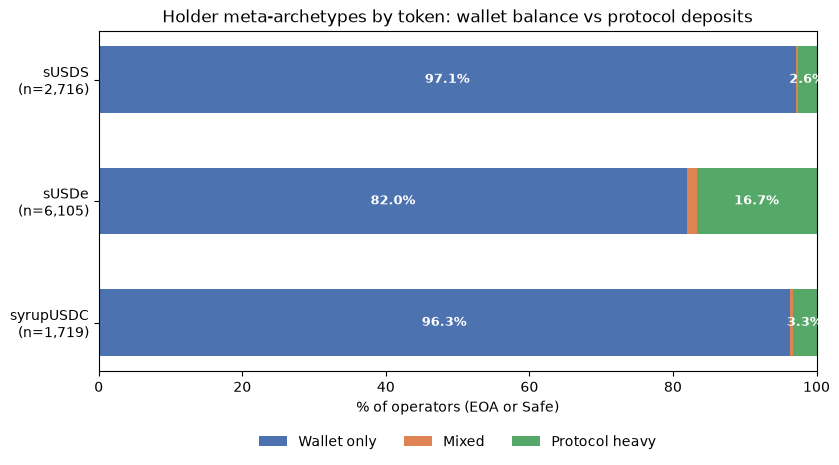

In [8]:
import matplotlib.pyplot as plt
import numpy as np

tokens = list(wallets_only.keys())
cats = ["wallet_only", "mixed", "protocol_heavy"]
cat_labels = {"wallet_only": "Wallet only", "mixed": "Mixed", "protocol_heavy": "Protocol heavy"}
colors = {"wallet_only": "#4C72B0", "mixed": "#DD8452", "protocol_heavy": "#55A868"}

counts = {t: wallets_only[t]["category"].value_counts() for t in tokens}
totals = {t: len(wallets_only[t]) for t in tokens}
pct = {t: {c: 100 * counts[t].get(c, 0) / totals[t] for c in cats} for t in tokens}

fig, ax = plt.subplots(figsize=(8.5, 4.8))
y = np.arange(len(tokens))
left = np.zeros(len(tokens))

for c in cats:
    vals = np.array([pct[t][c] for t in tokens])
    ax.barh(y, vals, left=left, color=colors[c], label=cat_labels[c], height=0.55)
    for i, (v, l) in enumerate(zip(vals, left)):
        if v > 2:
            ax.text(l + v/2, i, f"{v:.1f}%", ha="center", va="center",
                     fontsize=9, color="white", fontweight="bold")
    left += vals

ax.set_yticks(y)
ax.set_yticklabels([f"{t}\n(n={totals[t]:,})" for t in tokens])
ax.set_xlabel("% of operators (EOA or Safe)")
ax.set_xlim(0, 100)
ax.set_title("Holder meta-archetypes by token: wallet balance vs protocol deposits")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout()
save_fig("meta-archetype-mix.png")
plt.show()

In [9]:
eoa_all = pd.concat(
    [df.assign(token=tok) for tok, df in wallets_only.items()],
    ignore_index=True,
)

print("total_YBS_exposure quantiles (wallet + Morpho + Aave, ~USD):")
print(f"  p50 (median): ${eoa_all['total_YBS_exposure'].quantile(0.50):,.0f}  (half hold this or less)")
print(f"  p90:          ${eoa_all['total_YBS_exposure'].quantile(0.90):,.0f}  (top 10% hold more)")
print(f"  p95:          ${eoa_all['total_YBS_exposure'].quantile(0.95):,.0f}  (top 5% hold more)")
print(f"  p99:          ${eoa_all['total_YBS_exposure'].quantile(0.99):,.0f}  (top 1% hold more)")

WHALE_THRESHOLD = 1_000_000  # working cutoff, between p95 and p99
eoa_all["is_whale"] = eoa_all["total_YBS_exposure"] >= WHALE_THRESHOLD

n_whale = eoa_all["is_whale"].sum()
print(f"\nWhale threshold: >= ${WHALE_THRESHOLD:,.0f}")
print(f"Whales: {n_whale:,} / {len(eoa_all):,} ({100 * n_whale / len(eoa_all):.1f}%)")

total_YBS_exposure quantiles (wallet + Morpho + Aave, ~USD):
  p50 (median): $514  (half hold this or less)
  p90:          $165,416  (top 10% hold more)
  p95:          $552,957  (top 5% hold more)
  p99:          $4,129,333  (top 1% hold more)

Whale threshold: >= $1,000,000
Whales: 325 / 10,540 (3.1%)


In [10]:
rows = []
for token, df in wallets_only.items():
    on_morpho = df["YBS_in_morpho"] > EPSILON
    rows.append({
        "token": token,
        "eoa_holders": len(df),
        "morpho_users": int(on_morpho.sum()),
        "morpho_user_pct": round(100 * on_morpho.mean(), 2),
        "morpho_usd": round(df["YBS_in_morpho"].sum()),
        "wallet_usd": round(df["YBS_wallet_balance"].sum()),
        "morpho_share_of_exposure_pct": round(
            100 * df["YBS_in_morpho"].sum() / df["total_YBS_exposure"].sum(), 2
        ),
    })

q1 = pd.DataFrame(rows).set_index("token")
print("Q1  Morpho allocation by EOA holders")
q1

Q1  Morpho allocation by EOA holders


,eoa_holders,morpho_users,morpho_user_pct,morpho_usd,wallet_usd,morpho_share_of_exposure_pct
token,,,,,,
syrupUSDC,1719,64,3.72,103908631,150640182,40.82
sUSDe,6105,179,2.93,44528475,230167443,3.98
sUSDS,2716,78,2.87,54734342,2984196665,1.80


### Chart: Morpho adoption rate vs share of value, by token

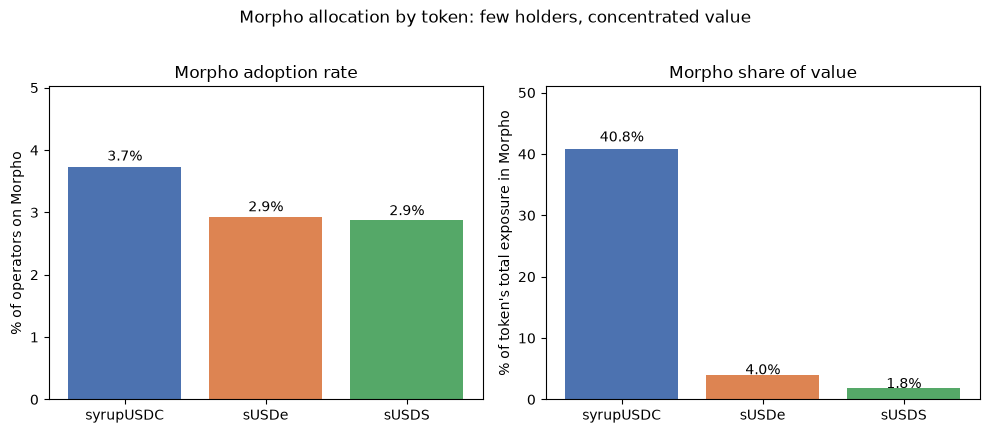

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
colors = {"syrupUSDC": "#4C72B0", "sUSDe": "#DD8452", "sUSDS": "#55A868"}
bar_colors = [colors[t] for t in q1.index]

axes[0].bar(q1.index, q1["morpho_user_pct"], color=bar_colors)
axes[0].set_ylabel("% of operators on Morpho")
axes[0].set_title("Morpho adoption rate")
for i, v in enumerate(q1["morpho_user_pct"]):
    axes[0].text(i, v + v * 0.03, f"{v:.1f}%", ha="center", fontsize=10)
axes[0].set_ylim(0, q1["morpho_user_pct"].max() * 1.35)

axes[1].bar(q1.index, q1["morpho_share_of_exposure_pct"], color=bar_colors)
axes[1].set_ylabel("% of token's total exposure in Morpho")
axes[1].set_title("Morpho share of value")
for i, v in enumerate(q1["morpho_share_of_exposure_pct"]):
    axes[1].text(i, v + v * 0.03, f"{v:.1f}%", ha="center", fontsize=10)
axes[1].set_ylim(0, q1["morpho_share_of_exposure_pct"].max() * 1.25)

fig.suptitle("Morpho allocation by token: few holders, concentrated value", y=1.02)
plt.tight_layout()
save_fig("allocation-concentration.png")
plt.show()

## Q: What whales are doing? -> in Morpho market breakdown notebook is also answer to that question!!!!

In [12]:
print("Q3  What are the whales doing?")

whales = eoa_all[eoa_all["is_whale"]]
print(f"Whales hold: ${whales['total_YBS_exposure'].sum():,.0f}")
print(f"All EOAs hold: ${eoa_all['total_YBS_exposure'].sum():,.0f}")
print(f"Whale share: {100 * whales['total_YBS_exposure'].sum() / eoa_all['total_YBS_exposure'].sum():.1f}%")
print()
print("Meta-archetype mix (all EOA):")
print(eoa_all["category"].value_counts(normalize=True).round(3))
print()
print("Meta-archetype mix (whales):")
print(whales["category"].value_counts())
print(whales["category"].value_counts(normalize=True).round(3))

protocol_users = eoa_all[eoa_all["category"].isin(["mixed", "protocol_heavy"])].sort_values(
    "total_YBS_exposure", ascending=False
)
protocol_users.to_csv("protocol_users_for_dune.csv", index=False)
print(f"\nExported {len(protocol_users):,} rows -> protocol_users_for_dune.csv")

Q3  What are the whales doing?
Whales hold: $3,986,943,559
All EOAs hold: $4,413,682,230
Whale share: 90.3%

Meta-archetype mix (all EOA):
category
wallet_only       0.882
protocol_heavy    0.109
mixed             0.009
Name: proportion, dtype: float64

Meta-archetype mix (whales):
category
wallet_only       221
protocol_heavy     97
mixed               7
Name: count, dtype: int64
category
wallet_only       0.680
protocol_heavy    0.298
mixed             0.022
Name: proportion, dtype: float64

Exported 1,241 rows -> protocol_users_for_dune.csv


In [13]:
import pandas as pd

df = pd.read_csv("protocol_users_for_dune.csv")

EPSILON = 1.0  # same threshold used earlier, to ignore dust

morpho_rows = df[df["YBS_in_morpho"] > EPSILON]

print(f"Rows with Morpho allocation: {len(morpho_rows)}")
print(f"Distinct wallets with Morpho allocation: {morpho_rows['wallet'].nunique()}")

print(morpho_rows.groupby("token")["wallet"].nunique())

Rows with Morpho allocation: 321
Distinct wallets with Morpho allocation: 306
token
sUSDS         78
sUSDe        179
syrupUSDC     64
Name: wallet, dtype: int64


###  syrup_morpho_wallets.csv, susde_morpho_wallets.csv, susds_morpho_wallets.csv
have been uploaded to Dune, can be access by dune.l2_research.dataset_syrup/susds/susde_morpho_wallets

In [14]:
syrup_morpho_wallets = df[
    (df["token"] == "syrupUSDC") & (df["YBS_in_morpho"] > EPSILON)
]["wallet"].unique()

pd.DataFrame({"wallet": syrup_morpho_wallets}).to_csv("syrup_morpho_wallets.csv", index=False)

In [15]:
susde_morpho_wallets = df[
    (df["token"] == "sUSDe") & (df["YBS_in_morpho"] > EPSILON)
]["wallet"].unique()
pd.DataFrame({"wallet": susde_morpho_wallets}).to_csv("susde_morpho_wallets.csv", index=False)

susds_morpho_wallets = df[
    (df["token"] == "sUSDS") & (df["YBS_in_morpho"] > EPSILON)
]["wallet"].unique()
pd.DataFrame({"wallet": susds_morpho_wallets}).to_csv("susds_morpho_wallets.csv", index=False)

In [16]:
# whale_flags.csv is the EOA-only base; the Morpho and Aave notebooks augment it
# with their own on-chain Safe detection, so this export is deliberately EOAs only.
eoa_all[eoa_all["optype"] == "eoa"][["wallet", "token", "is_whale"]].to_csv(
    "whale_flags.csv", index=False
)
